# CoT와 ReAct의 경계

**이 노트북에서 할 일**

1. 04절까지 쓴 과업 명세에서 출력 형식 한 글만 바꿔, 답만 받는 목록과 짧은 근거도 받는 목록을 만듭니다.
2. 두 목록을 같은 모델로 보내 기록표와 답 모양을 비교하고, 근거 줄의 사실을 입력 글과 대조합니다.
3. 추론 토큰 수와 도구 호출 목록을 확인하고, 판단 과정을 먼저 적게 한 목록을 한 번 더 보냅니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.

인터넷 서비스에 요청을 모두 3번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**강의와 실습 범위** — 강의 시간에는 3·7·8절(근거 목록, 근거 대조, 추론 토큰과 도구 호출)을 설명합니다.
4~6절과 9절(기록 함수, 두 목록 보내기와 비교, 값 바꿔 보기)은 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.10.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch07-prompt-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

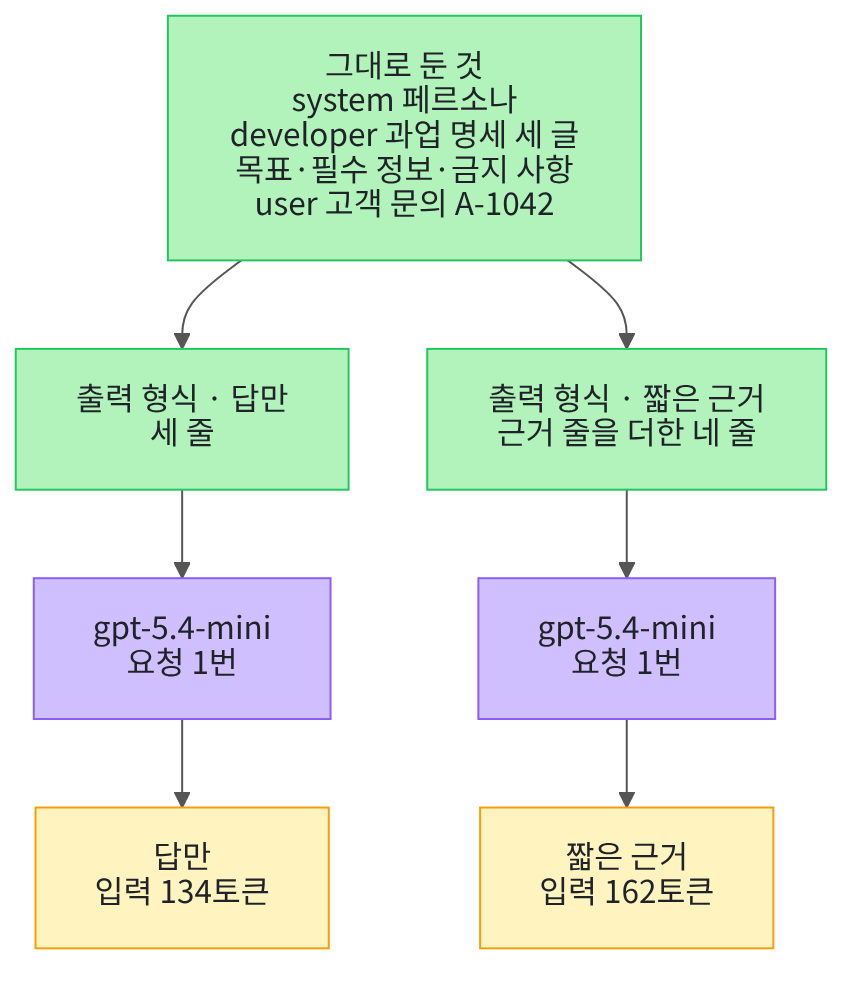

위에서 아래로 읽습니다. 맨 위 초록 상자는 두 목록에 똑같이 넣는 메시지와 과업 명세 세 글입니다.
두 목록은 출력 형식 한 글만 다르고, 짧은 근거 목록은 근거 줄 하나를 더 요청합니다.

두 목록을 같은 모델로 한 번씩 보냅니다. 맨 아래 노란 상자는 이 노트북에서 확인할 입력 토큰 수입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01~04절과 같은 실습 폴더와 같은 판입니다. 노트북은 앞 절 없이 새 커널에서 시작하므로 다시 확인합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `langchain-openai: 1.6.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

걸린 시간을 재는 모듈 `time`(Ch 6 05절)과 모델 객체를 만드는 함수를 불러옵니다.

In [2]:
# 시간을 재는 모듈과 모델 객체를 만드는 함수를 불러옵니다
import time

from langchain.chat_models import init_chat_model

01~04절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01~04절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

인자 `reasoning_effort="none"`은 Ch 6 01절에서 본 추론 설정입니다. 모델이 긴 추론 없이 바로 답하게 합니다.
이 설정이 사용량에 어떻게 남는지는 8절에서 확인합니다.

## 2. 04절까지 쓴 글로 답만 받는 목록 만들기

03절 예시 없음 목록과 04절 틀로 만든 목록은 같은 메시지였습니다. system 페르소나, developer 과업 명세, user 고객 문의입니다.
과업 명세의 출력 형식은 분류·다음 행동·고객 문장 세 줄만 요청합니다. 그래서 이 절은 이 목록을 「답만 받는 목록」으로 씁니다.

이 절에서 조건마다 바꾸는 것은 고객 문의가 아니라 developer 글입니다. 04절 틀은 developer 메시지를 객체로 고정해 두었습니다.
조건마다 틀을 새로 만들어야 하므로, 이 절은 03절처럼 튜플 목록으로 만듭니다.

In [5]:
# 04절과 같은 페르소나 글·고객 문의·과업 명세로 답만 받는 목록을 만듭니다
persona_text = "당신은 친절한 고객 상담원입니다."
inquiry_text = "어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다."
goal_text = "고객 문의를 분류하고 필요한 다음 행동을 안내하세요."
required_text = "회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요."
forbidden_text = "근거 없는 보상은 약속하지 마세요."
format_text = "분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요."
task_text = goal_text + "\n" + required_text + "\n" + forbidden_text + "\n" + format_text
answer_messages = [("system", persona_text), ("developer", task_text), ("user", inquiry_text)]
print("과업 명세:")
print(task_text)
print("답만 받는 목록의 메시지 수:", len(answer_messages))

과업 명세:
고객 문의를 분류하고 필요한 다음 행동을 안내하세요.
회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요.
근거 없는 보상은 약속하지 마세요.
분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.
답만 받는 목록의 메시지 수: 3


**결과 읽기** — 라벨 줄 `과업 명세:` 아래 네 줄은 02~04절과 같은 과업 명세입니다.
넷째 줄 `분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.`가 출력 형식입니다. 마지막 줄은 `답만 받는 목록의 메시지 수: 3`입니다.

## 3. 짧은 근거도 받는 목록 만들기

짧은 근거(brief evidence)는 답을 검토하는 사람이 입력 글에서 다시 찾을 수 있는 사실을 짧게 적은 줄입니다.
회의록에 「3쪽 표 참고」라고 적어 두면, 읽는 사람이 그 쪽을 다시 펼쳐 볼 수 있는 것과 비슷합니다.
이 절에서는 출력 형식에 근거 줄 하나를 더합니다. 근거 줄에는 고객 문의와 회사 규정에서 다시 찾을 수 있는 사실만 적게 합니다.

바꾸는 글은 출력 형식 하나입니다. 03절처럼 한 곳만 다르게 해야, 달라진 결과를 그 글과 이어 읽을 수 있습니다.
긴 글은 03절처럼 같은 이름에 `+`로 이어 다시 담습니다. 마지막 세 줄은 system·user 메시지가 두 목록에서 같은지 확인합니다.

In [6]:
# 출력 형식 한 글만 바꿔, 근거 줄을 더한 과업 명세와 목록을 만듭니다
evidence_format_text = "분류, 근거, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 네 줄로 답하세요."
evidence_format_text = evidence_format_text + " 근거 줄에는 고객 문의와 회사 규정에서 다시 찾을 수 있는 사실만 짧게 적으세요."
evidence_task_text = goal_text + "\n" + required_text + "\n" + forbidden_text + "\n" + evidence_format_text
evidence_messages = [("system", persona_text), ("developer", evidence_task_text), ("user", inquiry_text)]
print("바꾼 출력 형식:")
print(evidence_format_text)
same_system_user = answer_messages[0] == evidence_messages[0] and answer_messages[2] == evidence_messages[2]
print("system과 user 메시지가 같은가:", same_system_user)
assert same_system_user

바꾼 출력 형식:
분류, 근거, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 네 줄로 답하세요. 근거 줄에는 고객 문의와 회사 규정에서 다시 찾을 수 있는 사실만 짧게 적으세요.
system과 user 메시지가 같은가: True


**결과 읽기** — 라벨 줄 `바꾼 출력 형식:` 아래 줄은 `분류, 근거, 다음 행동`으로 시작하고, 근거 줄에 적을 내용까지 두 문장입니다.
마지막 줄은 `system과 user 메시지가 같은가: True`이고, `assert`도 통과했습니다.
두 목록에서 다른 곳은 developer 글의 출력 형식뿐입니다.

## 4. 기록을 만드는 함수 두 개

01~04절과 같은 함수 두 개로 요청마다 기록 한 줄을 만듭니다. 먼저 `timed_invoke()` 함수를 정의합니다.
Ch 6 06절과 같은 코드입니다. 요청을 보내면서 걸린 시간을 재고, 응답 객체와 걸린 초를 튜플로 반환합니다.
이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [7]:
# 모델 객체로 메시지 목록을 보내고, 응답 객체와 걸린 초를 튜플로 반환하는 함수를 정의합니다
def timed_invoke(run_model, input_messages):
    start_time = time.perf_counter()
    run_response = run_model.invoke(input_messages)
    run_elapsed = time.perf_counter() - start_time
    return run_response, run_elapsed

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

둘째 함수 `make_prompt_record()`는 01~04절과 같은 코드입니다. 조건 이름·응답 객체·걸린 초로 딕셔너리 한 줄을 만듭니다.
키는 `조건`·`답`·`입력 토큰 수`·`출력 토큰 수`·`끝난 이유`·`걸린 초` 여섯 개입니다.
이 셀도 함수를 정의만 하므로 출력이 없습니다.

In [8]:
# 조건 이름·응답 객체·걸린 초로 기록 한 줄(딕셔너리)을 만드는 함수를 정의합니다
def make_prompt_record(condition, run_response, run_elapsed):
    run_usage = run_response.usage_metadata
    record = {
        "조건": condition,
        "답": run_response.text,
        "입력 토큰 수": run_usage["input_tokens"],
        "출력 토큰 수": run_usage["output_tokens"],
        "끝난 이유": run_response.response_metadata["finish_reason"],
        "걸린 초": round(run_elapsed, 2),
    }
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 5. 두 목록 보내기

먼저 답만 받는 목록을 보냅니다. 요청은 여기서 처음 나갑니다.
실행 전에 예상합니다. 03·04절과 같은 목록이므로 답은 세 줄이고, 입력 토큰 수는 134일 것입니다.

In [9]:
# 답만 받는 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
answer_response, answer_elapsed = timed_invoke(model, answer_messages)
answer_record = make_prompt_record("답만", answer_response, answer_elapsed)
print("답:")
print(answer_record["답"])

답:
분류: 교환/파손 접수  
다음 행동: 파손 부위가 보이는 사진을 보내주시면 교환 접수를 도와드리겠습니다. 주문번호 A-1042 확인했습니다.  
고객에게 보낼 한 문장: 주문번호 A-1042 확인되었으며, 깨진 뚜껑 사진을 보내주시면 새 상품 교환 가능 여부를 바로 안내드리겠습니다.


**결과 읽기** — 라벨 줄 아래 세 줄은 `분류: 교환/파손 접수`, `다음 행동:`, `고객에게 보낼 한 문장:`으로 시작합니다.
다음 행동 줄 끝에 `주문번호 A-1042 확인했습니다.`가 있고, 두 줄에 사진 요청이 있습니다. 보상 약속은 없었습니다.
답은 결론만 적었고, 왜 교환 접수인지는 적지 않았습니다.

답은 「확인했습니다」라고 적었지만, 이 요청은 주문 기록을 찾아보지 않았습니다. 이 점은 8절에서 다시 봅니다.
분류 이름은 04절 답 「교환 요청(파손)」과 달랐습니다. 03절에서 본 것처럼 같은 목록도 실행마다 낱말이 달라질 수 있습니다.

이번에는 짧은 근거도 받는 목록을 같은 모델로 보냅니다. 바꾼 것은 넘기는 목록 하나입니다.
실행 전에 예상합니다. 답이 네 줄이 되고, 둘째 줄이 근거 줄일 것입니다.

In [10]:
# 짧은 근거도 받는 목록을 같은 모델로 보내고 기록 한 줄을 만듭니다(요청 1번)
evidence_response, evidence_elapsed = timed_invoke(model, evidence_messages)
evidence_record = make_prompt_record("짧은 근거", evidence_response, evidence_elapsed)
print("답:")
print(evidence_record["답"])

답:
분류: 교환 요청  
근거: 어제 받은 텀블러 뚜껑이 깨졌고, 새 상품으로 바꾸고 싶다고 하셨습니다. 회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 A-1042입니다.  
다음 행동: 파손된 뚜껑 사진을 보내주시면 교환 접수를 도와드리겠습니다.  
고객에게 보낼 한 문장: 파손 사진을 보내주시면 주문번호 A-1042 기준으로 교환 접수를 진행해드리겠습니다.


**결과 읽기** — 라벨 줄 아래 네 줄은 `분류: 교환 요청`, `근거:`, `다음 행동:`, `고객에게 보낼 한 문장:`으로 시작합니다.
예상대로 둘째 줄이 근거 줄입니다. 근거 줄은 세 문장으로, 고객이 한 말·회사 규정·주문번호를 차례로 적었습니다.
다음 행동 줄과 고객 문장 줄에도 사진 요청이 있고, 보상 약속은 없었습니다.

## 6. 기록표와 답 모양 비교

두 기록을 01~04절과 같은 기록표 모양으로 출력합니다. 마지막 두 줄은 근거 요청이 더한 입력·출력 토큰 수입니다.
실행 전에 예상합니다. 출력 형식 글이 길어진 만큼 입력 토큰이 늘고, 근거 줄만큼 출력 토큰도 늘 것입니다.

In [11]:
# 두 기록을 기록표 모양으로 출력하고, 근거 요청이 더한 입력·출력 토큰 수를 계산합니다
two_records = [answer_record, evidence_record]
print("기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):")
for record in two_records:
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", record["끝난 이유"], "|", record["걸린 초"])
added_input = evidence_record["입력 토큰 수"] - answer_record["입력 토큰 수"]
added_output = evidence_record["출력 토큰 수"] - answer_record["출력 토큰 수"]
print("근거 요청이 더한 입력 토큰 수:", added_input)
print("근거 요청이 더한 출력 토큰 수:", added_output)

기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):
답만 | 134 | 95 | stop | 1.06
짧은 근거 | 162 | 130 | stop | 1.72
근거 요청이 더한 입력 토큰 수: 28
근거 요청이 더한 출력 토큰 수: 35


**결과 읽기** — 라벨 줄 아래 두 줄은 `답만 | 134 | 95 | stop | 1.06`과 `짧은 근거 | 162 | 130 | stop | 1.72`입니다.
마지막 두 줄은 `근거 요청이 더한 입력 토큰 수: 28`과 `근거 요청이 더한 출력 토큰 수: 35`입니다.
입력 134는 03·04절 목록과 같습니다. 바꾼 출력 형식 글은 입력 토큰을 28개 더했습니다.

교재를 만들 때 앞선 새 커널 실행에서는 출력 토큰이 108·121로, 차이가 13이었습니다.
걸린 초도 앞선 실행은 2.0·1.4초로 이번과 순서가 반대였습니다. 한 번씩 잰 시간이라, 근거를 요청하면 느려진다고 말하지 않습니다.

02절에서 배운 대로 답의 글자 수는 `len(글)`, 줄 수는 `split("\n")` 목록의 길이로 셉니다.
실행 전에 예상합니다. 짧은 근거 답이 한 줄 더 많을 것입니다.

In [12]:
# 두 답의 글자 수와 줄 수(빈 줄 포함)를 셉니다
print("조건 | 글자 수 | 줄 수(빈 줄 포함)")
for record in two_records:
    answer_lines = record["답"].split("\n")
    print(record["조건"], "|", len(record["답"]), "|", len(answer_lines))

조건 | 글자 수 | 줄 수(빈 줄 포함)
답만 | 159 | 3
짧은 근거 | 209 | 4


**결과 읽기** — 라벨 줄 아래 두 줄은 `답만 | 159 | 3`과 `짧은 근거 | 209 | 4`입니다.
예상대로 짧은 근거 답이 한 줄 더 많았고, 글자 수는 50자 늘었습니다.
원문을 보면 근거 줄이 더해진 대신, 다음 행동 줄과 고객 문장 줄은 답만 받은 답보다 짧았습니다.

## 7. 근거 줄을 입력 글과 대조하기

답에 근거 줄이 있다고 근거가 맞는 것은 아닙니다. 근거 줄의 사실이 입력 글에 정말 있는지는 사람이 대조해야 합니다.
먼저 짧은 근거 답을 줄마다 잘라, 「근거」 낱말이 든 첫 줄을 찾습니다.
찾으면 `break`로 반복을 멈춥니다(Ch 2 03절). 찾지 못하면 처음 담아 둔 글 「근거 줄 없음」이 남습니다.

In [13]:
# 짧은 근거 답을 줄마다 잘라, 「근거」 낱말이 든 첫 줄을 찾습니다
evidence_line = "근거 줄 없음"
for line in evidence_record["답"].split("\n"):
    if "근거" in line:
        evidence_line = line
        break
print("근거 줄:")
print(evidence_line)

근거 줄:
근거: 어제 받은 텀블러 뚜껑이 깨졌고, 새 상품으로 바꾸고 싶다고 하셨습니다. 회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 A-1042입니다.  


**결과 읽기** — 라벨 줄 `근거 줄:` 아래 줄은 `근거: 어제 받은 텀블러 뚜껑이 깨졌고, 새 상품으로 바꾸고 싶다고 하셨습니다.`로 시작합니다.
이어서 `회사 규정상 교환 접수에는 파손 사진이 필요합니다.`와 `주문번호는 A-1042입니다.`가 있습니다.

세 문장을 입력 글과 하나씩 대조합니다. 첫 문장은 고객 문의의 첫 문장과 셋째 문장을 한 문장으로 줄인 것입니다.
둘째 문장은 과업 명세 필수 정보의 첫 문장과 글자까지 같습니다. 셋째 문장은 고객 문의 둘째 문장과 같습니다.
이 근거 줄에서 입력 글에 없는 사실은 찾지 못했습니다.

앞선 새 커널 실행의 근거 줄은 고객이 한 말 한 문장뿐이었습니다. 출력 형식은 회사 규정의 사실도 적으라고 했지만, 규정이 빠졌습니다.
근거 줄이 무엇을 빠뜨렸는지도 입력 글과 대조해야 알 수 있습니다.

01절 확인 단어 세 개가 고객 문의·과업 명세·근거 줄 가운데 어디에 있는지 표시합니다.
이 표시도 품질 점수가 아니라, 원문을 대조할 곳을 찾는 도구입니다.
실행 전에 예상합니다. 주문번호 A-1042는 고객 문의에, 교환과 사진은 과업 명세의 필수 정보에 있을 것입니다.

In [14]:
# 확인 단어 세 개가 고객 문의·과업 명세·근거 줄 가운데 어디에 있는지 표시합니다
check_words = ["교환", "A-1042", "사진"]
print("확인 단어 | 고객 문의 | 과업 명세 | 근거 줄")
for word in check_words:
    in_inquiry = word in inquiry_text
    in_task = word in evidence_task_text
    in_evidence = word in evidence_line
    print(word, "|", in_inquiry, "|", in_task, "|", in_evidence)

확인 단어 | 고객 문의 | 과업 명세 | 근거 줄
교환 | False | True | True
A-1042 | True | False | True
사진 | False | True | True


**결과 읽기** — 라벨 줄 아래 세 줄은 `교환 | False | True | True`, `A-1042 | True | False | True`, `사진 | False | True | True`입니다.
고객 문의·과업 명세 두 열은 예상과 같습니다. 근거 줄 열은 세 줄 모두 `True`입니다.

표시가 모두 `True`여도 근거 줄이 맞다는 뜻은 아닙니다. 같은 낱말이 있는지만 알려 줍니다.
앞선 새 커널 실행에서는 근거 줄 열이 세 줄 모두 False였습니다. 그 근거 줄은 「교환」 대신 「바꾸고 싶다」라고 적었고, 번호와 규정은 없었습니다.
낱말 표시로 읽을 곳을 찾고, 뜻은 앞 셀처럼 문장을 나란히 읽어 확인합니다.

## 8. 추론 토큰 수와 도구 호출 목록 확인하기

답에 「확인했습니다」 같은 말이 있어도, 무엇을 조회했다는 기록은 아닙니다. 이 요청에서 모델은 글을 만들었을 뿐입니다.
응답 객체에서 두 가지를 확인합니다.

첫째는 Ch 6 06절에서 본 `output_token_details`의 `reasoning` 값입니다. 모델이 답 전에 따로 쓴 추론 토큰 수입니다.
둘째는 응답 객체의 속성 `tool_calls`입니다. 모델이 프로그램에 요청한 도구 호출의 목록입니다.

이 노트북은 모델에 도구를 알려 주지 않았습니다. 도구를 알려 주고 호출 요청을 받는 방법은 Ch 19에서 배웁니다.

실행 전에 예상합니다. 추론 토큰 수는 0이고, 도구 호출 목록은 빈 목록 `[]`일 것입니다.

In [15]:
# 두 응답의 추론 토큰 수와 도구 호출 목록을 봅니다
response_pairs = [("답만", answer_response), ("짧은 근거", evidence_response)]
print("조건 | 추론 토큰 수 | 도구 호출 목록")
for condition, run_response in response_pairs:
    output_details = run_response.usage_metadata["output_token_details"]
    print(condition, "|", output_details["reasoning"], "|", run_response.tool_calls)
    assert run_response.tool_calls == []

조건 | 추론 토큰 수 | 도구 호출 목록
답만 | 0 | []
짧은 근거 | 0 | []


**결과 읽기** — 라벨 줄 아래 두 줄은 `답만 | 0 | []`과 `짧은 근거 | 0 | []`입니다. `assert`도 통과했습니다.
두 응답 모두 추론 토큰은 0이고, 도구 호출 목록은 비어 있습니다.

5절 답만 받은 답에는 「주문번호 A-1042 확인했습니다」라는 말이 있었습니다. 그러나 이 요청에는 주문 기록을 찾는 도구가 없었습니다.
모델도 도구 호출을 요청하지 않았습니다. 번호는 고객 문의 글에 있던 것을 옮겨 적었을 뿐입니다.
답의 「확인」은 무엇을 실행한 기록이 아니라, 모델이 만든 글입니다.

추론 토큰 0은 답 전에 따로 쓴 추론이 없었다는 뜻입니다. 근거 줄은 답과 함께 출력 토큰으로 셌습니다.
근거 줄은 사람이 읽도록 쓴 글입니다. 모델이 답을 정한 실제 과정을 그대로 옮겼다는 증거는 없습니다.

## 9. 값 바꿔 보기 — 판단 과정을 먼저 적게 하기

사고의 연쇄(Chain of Thought, CoT)는 답 전에 중간 단계를 글로 적게 하는 프롬프트 방법입니다.
수학 시험에서 답만 쓰지 않고 풀이를 답안지에 적는 것과 비슷합니다.
공식 안내 가운데 OpenAI의 gpt-5.4 모델 안내는 추론 설정이 none이면 답 전에 단계를 적게 해 보라고 권합니다.
이 안내는 2026-09-17에 확인했습니다.

바꾸는 값은 이번에도 출력 형식 한 글입니다. 짧은 근거 대신 「답하기 전에 판단 과정을 단계별로 자세히 적으세요」를 넣습니다.
나머지 세 줄은 답만 받는 목록과 같은 형식입니다. 이 셀은 목록만 만들고 요청을 보내지 않습니다.

In [16]:
# 출력 형식 한 글만, 판단 과정을 먼저 단계별로 적게 바꾼 목록을 만듭니다
steps_format_text = "답하기 전에 판단 과정을 단계별로 자세히 적으세요."
steps_format_text = steps_format_text + " 그다음 분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요."
steps_task_text = goal_text + "\n" + required_text + "\n" + forbidden_text + "\n" + steps_format_text
steps_messages = [("system", persona_text), ("developer", steps_task_text), ("user", inquiry_text)]
print("바꾼 출력 형식:")
print(steps_format_text)

바꾼 출력 형식:
답하기 전에 판단 과정을 단계별로 자세히 적으세요. 그다음 분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.


**결과 읽기** — 라벨 줄 `바꾼 출력 형식:` 아래 줄은 `답하기 전에 판단 과정을 단계별로 자세히 적으세요.`로 시작합니다.
뒤 문장은 답만 받는 목록과 같은 세 줄 형식입니다.

이 목록을 보냅니다. 실행 전에 예상합니다. 판단 과정 글이 앞에 붙어 답이 여러 줄로 길어지고, 출력 토큰이 가장 많을 것입니다.

In [17]:
# 판단 과정을 먼저 적게 한 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
steps_response, steps_elapsed = timed_invoke(model, steps_messages)
steps_record = make_prompt_record("단계별 판단 과정", steps_response, steps_elapsed)
print("답:")
print(steps_record["답"])

답:
판단 과정: 파손이 있는 교환 요청으로 분류됩니다. 교환 접수에는 파손 사진이 필요하므로, 사진 확인 전에는 교환 확정이나 보상을 약속할 수 없습니다. 주문번호 A-1042를 기준으로 안내합니다.  
분류: 파손 교환 요청  
다음 행동: 깨진 뚜껑의 사진을 보내주시면 교환 접수를 진행하겠습니다.  
고객에게 보낼 한 문장: 주문번호 A-1042 확인되었으며, 깨진 뚜껑 사진을 보내주시면 새 상품 교환 가능 여부를 바로 안내드리겠습니다.


**결과 읽기** — 라벨 줄 아래 네 줄은 `판단 과정:`, `분류: 파손 교환 요청`, `다음 행동:`, `고객에게 보낼 한 문장:`으로 시작합니다.
「단계별로 자세히」라고 적었지만, 판단 과정은 한 줄에 세 문장이었고 번호 붙인 단계는 없었습니다.
고객 문장 줄은 `주문번호 A-1042 확인되었으며,`로 시작하고, 보상 약속은 없었습니다.

판단 과정 줄의 세 문장을 입력 글과 대조합니다. 파손 사진이 필요하다는 규정과 주문번호 A-1042는 입력에 있습니다.
「사진 확인 전에는 교환 확정이나 보상을 약속할 수 없습니다」는 입력에 그대로 있는 문장이 아닙니다.
필수 정보와 금지 사항을 이어, 모델이 덧붙인 판단입니다.

탐색 실행 두 번과 앞선 새 커널 실행에서도 판단 과정은 한 줄이었습니다. 탐색 한 번은 문구가 조금 다른 출력 형식이었습니다.
지금 문구로는 세 번 본 모양이지만, 이 출력 형식이 늘 한 줄 판단 과정을 만든다고 말하지는 않습니다.

세 조건을 한 줄씩 나란히 봅니다. 입력·출력 토큰 수, 글자 수, 줄 수, 추론 토큰 수를 출력합니다.
기록과 응답 객체를 튜플로 묶어 반복하고, 각 줄의 값은 앞 셀들과 같은 방법으로 셉니다.

In [18]:
# 세 조건을 입력·출력 토큰 수, 글자 수, 줄 수, 추론 토큰 수로 나란히 봅니다
all_pairs = [(answer_record, answer_response), (evidence_record, evidence_response), (steps_record, steps_response)]
print("조건 | 입력 토큰 수 | 출력 토큰 수 | 글자 수 | 줄 수 | 추론 토큰 수")
for record, run_response in all_pairs:
    line_count = len(record["답"].split("\n"))
    reasoning_count = run_response.usage_metadata["output_token_details"]["reasoning"]
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", len(record["답"]), "|", line_count, "|", reasoning_count)

조건 | 입력 토큰 수 | 출력 토큰 수 | 글자 수 | 줄 수 | 추론 토큰 수
답만 | 134 | 95 | 159 | 3 | 0
짧은 근거 | 162 | 130 | 209 | 4 | 0
단계별 판단 과정 | 152 | 148 | 246 | 4 | 0


**결과 읽기** — 라벨 줄 아래 첫 두 줄은 `답만 | 134 | 95 | 159 | 3 | 0`과 `짧은 근거 | 162 | 130 | 209 | 4 | 0`입니다.
셋째 줄은 `단계별 판단 과정 | 152 | 148 | 246 | 4 | 0`입니다.
출력 토큰은 판단 과정을 적게 한 조건이 148로 가장 많았고, 세 조건 모두 추론 토큰은 0이었습니다.

판단 과정 글도 근거 줄처럼 출력 토큰으로 셉니다. 적게 한 글이 길수록 출력 토큰도 늘어납니다.
앞선 새 커널 실행의 출력 토큰은 108·121·155였습니다. 판단 과정 조건이 가장 많은 것은 두 번 같았습니다.

## 실험 결과 해석

출력 형식 한 글만 바꾸자 답 모양이 바뀌었습니다. 짧은 근거 목록의 답은 근거 줄이 더해진 네 줄이었습니다.

입력 토큰은 28개, 출력 토큰은 35개 늘었습니다. 근거 줄의 세 문장은 모두 고객 문의와 필수 정보에서 다시 찾을 수 있었습니다.
앞선 실행의 근거 줄은 회사 규정을 빠뜨렸습니다. 근거 줄도 입력 글과 대조해야 합니다.

답에 「확인했습니다」가 있어도 도구 호출 목록은 비어 있었습니다. 조건마다 요청은 한 번뿐입니다.
모델이 도구를 고르고, 프로그램이 실행한 결과를 받아 다시 판단하는 반복(ReAct)은 이 노트북에 없습니다.

판단 과정을 먼저 적게 하자 출력 토큰이 가장 많았습니다. 판단 과정 줄에는 입력에 그대로 있지 않고, 필수 정보와 금지 사항을 이어 모델이 덧붙인 판단도 섞였습니다.
이 글도 사람이 읽는 출력이라, 근거 줄과 같은 방법으로 대조합니다. 답의 정확성이 좋아졌는지는 판정하지 않았습니다.

이 결론은 고객 문의 하나·모델 하나·조건마다 한 번 실행한 범위입니다. 걸린 초는 앞선 실행과 순서가 반대라 속도 차이로 읽지 않습니다.

## 정리

- 출력 형식 한 글만 바꿔 근거 줄을 요청했고, 근거 줄의 사실은 입력 글과 한 문장씩 대조했습니다.
- 두 응답 모두 추론 토큰 0, 도구 호출 목록 `[]`이었고, 답의 「확인했습니다」는 조회 기록이 아니었습니다.
- 판단 과정을 먼저 적게 하자 출력 토큰이 늘었습니다. 그 글에는 입력에 그대로 있지 않고, 필수 정보와 금지 사항을 이어 모델이 덧붙인 판단도 섞였습니다.

다음 06절에서는 같은 목록을 여러 번 따로 보내고, 답마다 분류 줄만 모아 비교합니다.